<a href="https://colab.research.google.com/github/ayush-singh110/AI_TEXT_DETECTION/blob/main/Trader_Behavior_Insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df1=pd.read_csv('historical_data.csv')
df1.head()

,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,02-12-2024 22:50,0.000000,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,02-12-2024 22:50,986.524596,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,02-12-2024 22:50,1002.518996,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,BUY,02-12-2024 22:50,1146.558564,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050043,1.080000e+15,1.730000e+12
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,BUY,02-12-2024 22:50,1289.488521,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.003055,1.050000e+15,1.730000e+12


In [3]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211224 entries, 0 to 211223
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Account           211224 non-null  object 
 1   Coin              211224 non-null  object 
 2   Execution Price   211224 non-null  float64
 3   Size Tokens       211224 non-null  float64
 4   Size USD          211224 non-null  float64
 5   Side              211224 non-null  object 
 6   Timestamp IST     211224 non-null  object 
 7   Start Position    211224 non-null  float64
 8   Direction         211224 non-null  object 
 9   Closed PnL        211224 non-null  float64
 10  Transaction Hash  211224 non-null  object 
 11  Order ID          211224 non-null  int64  
 12  Crossed           211224 non-null  bool   
 13  Fee               211224 non-null  float64
 14  Trade ID          211224 non-null  float64
 15  Timestamp         211224 non-null  float64
dtypes: bool(1), float64(

In [4]:
df1['Account'].value_counts()

,count
Account,
0xbee1707d6b44d4d52bfe19e41f8a828645437aab,40184
0xbaaaf6571ab7d571043ff1e313a9609a10637864,21192
0xa0feb3725a9335f49874d7cd8eaad6be45b27416,15605
0x8477e447846c758f5a675856001ea72298fd9cb5,14998
0xb1231a4a2dd02f2276fa3c5e2a2f3436e6bfed23,14733
0x28736f43f1e871e6aa8b1148d38d4994275d72c4,13311
0x513b8629fe877bb581bf244e326a047b249c4ff1,12236
0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4,9893
0x47add9a56df66b524d5e2c1993a43cde53b6ed85,8519


In [5]:
df1['Order ID'].value_counts()

,count
Order ID,
61636246980,390
78766167752,372
76557824768,366
86618342363,354
78766120810,298
...,...
88363778895,1
88363808596,1
55379734663,1


In [6]:
df1.drop(['Transaction Hash','Side'],axis=1,inplace=True)

In [7]:
df1.duplicated().sum()

np.int64(0)

In [8]:
df1.head()

,Account,Coin,Execution Price,Size Tokens,Size USD,Timestamp IST,Start Position,Direction,Closed PnL,Order ID,Crossed,Fee,Trade ID,Timestamp
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,02-12-2024 22:50,0.000000,Buy,0.0,52017706630,True,0.345404,8.950000e+14,1.730000e+12
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,02-12-2024 22:50,986.524596,Buy,0.0,52017706630,True,0.005600,4.430000e+14,1.730000e+12
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,02-12-2024 22:50,1002.518996,Buy,0.0,52017706630,True,0.050431,6.600000e+14,1.730000e+12
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,02-12-2024 22:50,1146.558564,Buy,0.0,52017706630,True,0.050043,1.080000e+15,1.730000e+12
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,02-12-2024 22:50,1289.488521,Buy,0.0,52017706630,True,0.003055,1.050000e+15,1.730000e+12


In [9]:
df2=pd.read_csv('fear_greed_index.csv')
df2.head()

,timestamp,value,classification,date
0,1517463000,30,Fear,2018-02-01
1,1517549400,15,Extreme Fear,2018-02-02
2,1517635800,40,Fear,2018-02-03
3,1517722200,24,Extreme Fear,2018-02-04
4,1517808600,11,Extreme Fear,2018-02-05


In [10]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   timestamp       2644 non-null   int64 
 1   value           2644 non-null   int64 
 2   classification  2644 non-null   object
 3   date            2644 non-null   object
dtypes: int64(2), object(2)
memory usage: 82.8+ KB


In [11]:
df2.duplicated().sum()

np.int64(0)

In [12]:
df1['Timestamp']=pd.to_datetime(df1['Timestamp IST'], format='%d-%m-%Y %H:%M').dt.date
df2['Timestamp']=pd.to_datetime(df2['date'], format='%Y-%m-%d').dt.date

In [13]:
final_df=pd.merge(df1,df2,on='Timestamp',how='left')

In [14]:
final_df.head()

,Account,Coin,Execution Price,Size Tokens,Size USD,Timestamp IST,Start Position,Direction,Closed PnL,Order ID,Crossed,Fee,Trade ID,Timestamp,timestamp,value,classification,date
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,02-12-2024 22:50,0.000000,Buy,0.0,52017706630,True,0.345404,8.950000e+14,2024-12-02,1.733117e+09,80.0,Extreme Greed,2024-12-02
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,02-12-2024 22:50,986.524596,Buy,0.0,52017706630,True,0.005600,4.430000e+14,2024-12-02,1.733117e+09,80.0,Extreme Greed,2024-12-02
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,02-12-2024 22:50,1002.518996,Buy,0.0,52017706630,True,0.050431,6.600000e+14,2024-12-02,1.733117e+09,80.0,Extreme Greed,2024-12-02
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,02-12-2024 22:50,1146.558564,Buy,0.0,52017706630,True,0.050043,1.080000e+15,2024-12-02,1.733117e+09,80.0,Extreme Greed,2024-12-02
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,02-12-2024 22:50,1289.488521,Buy,0.0,52017706630,True,0.003055,1.050000e+15,2024-12-02,1.733117e+09,80.0,Extreme Greed,2024-12-02


In [15]:
final_df.isnull().sum()

,0
Account,0
Coin,0
Execution Price,0
Size Tokens,0
Size USD,0
Timestamp IST,0
Start Position,0
Direction,0
Closed PnL,0
Order ID,0


In [16]:
final_df.duplicated().sum()

np.int64(0)

In [17]:
final_df.drop(['Timestamp IST','date','timestamp'],axis=1,inplace=True)

In [18]:
final_df.dropna(inplace=True)

In [19]:
final_df['classification'].value_counts()

,count
classification,
Fear,61837
Greed,50303
Extreme Greed,39992
Neutral,37686
Extreme Fear,21400


In [20]:
final_df['classification']=final_df['classification'].replace('Extreme Greed','Greed')
final_df['classification']=final_df['classification'].replace('Extreme Fear','Fear')

In [21]:
final_df['classification'].value_counts()

,count
classification,
Greed,90295
Fear,83237
Neutral,37686


In [22]:
final_df.isnull().sum()

,0
Account,0
Coin,0
Execution Price,0
Size Tokens,0
Size USD,0
Start Position,0
Direction,0
Closed PnL,0
Order ID,0
Crossed,0


In [23]:
final_df.head()

,Account,Coin,Execution Price,Size Tokens,Size USD,Start Position,Direction,Closed PnL,Order ID,Crossed,Fee,Trade ID,Timestamp,value,classification
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,0.000000,Buy,0.0,52017706630,True,0.345404,8.950000e+14,2024-12-02,80.0,Greed
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,986.524596,Buy,0.0,52017706630,True,0.005600,4.430000e+14,2024-12-02,80.0,Greed
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,1002.518996,Buy,0.0,52017706630,True,0.050431,6.600000e+14,2024-12-02,80.0,Greed
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,1146.558564,Buy,0.0,52017706630,True,0.050043,1.080000e+15,2024-12-02,80.0,Greed
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,1289.488521,Buy,0.0,52017706630,True,0.003055,1.050000e+15,2024-12-02,80.0,Greed


In [24]:
final_df['Coin'].value_counts()

,count
Coin,
HYPE,68005
@107,29992
BTC,26064
ETH,11158
SOL,10691
...,...
@18,1
@30,1
@25,1


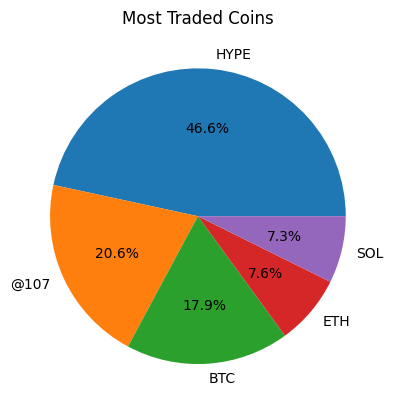

In [25]:
# Most Traded Coins
coins_count=final_df['Coin'].value_counts().head(5)
plt.pie(coins_count,labels=coins_count.index,autopct='%1.1f%%')
plt.title("Most Traded Coins")
plt.show()

## HYPE is the most Traded Coin

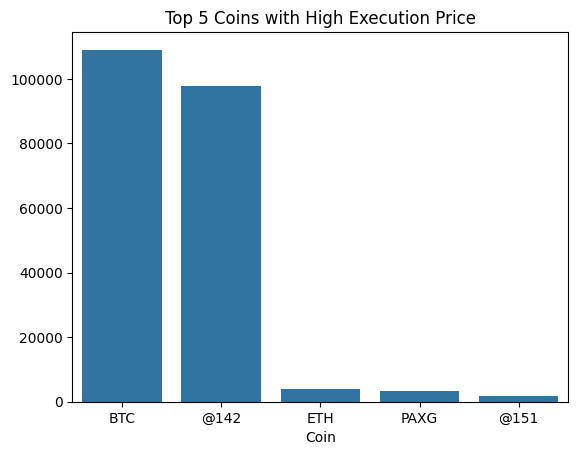

In [26]:
## Top 5 Coins with high Execution Price
max_exc_coin=final_df.groupby('Coin')['Execution Price'].max().sort_values(ascending=False).head(5)
sns.barplot(x=max_exc_coin.index,y=max_exc_coin.values)
plt.title('Top 5 Coins with High Execution Price')
plt.show()

## BTC,@142 are the coins with High Execution Price

In [27]:
final_df['Direction'].value_counts()

,count
Direction,
Open Long,49895
Close Long,48678
Open Short,39741
Close Short,36007
Sell,19902
Buy,16716
Spot Dust Conversion,142
Short > Long,70
Long > Short,57


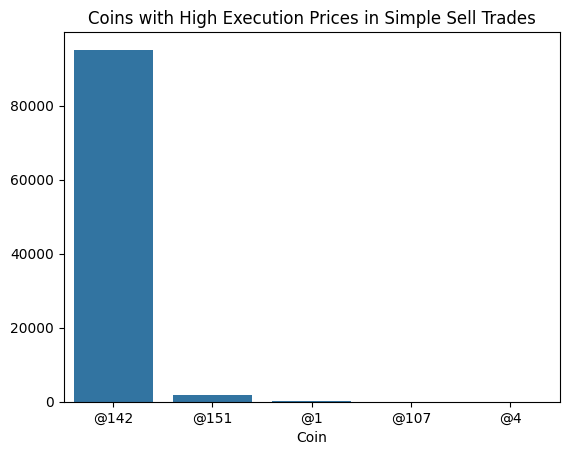

In [28]:
##Coins with High Execution Prices in Simple Sell Trades
coin_sell=final_df[final_df['Direction']=='Sell']
coin_sell_p=coin_sell.groupby('Coin')['Execution Price'].max().sort_values(ascending=False).head(5)
sns.barplot(x=coin_sell_p.index,y=coin_sell_p.values)
plt.title('Coins with High Execution Prices in Simple Sell Trades')
plt.show()

## @142 is the coin with High Execution Price in Simple Sell Trade

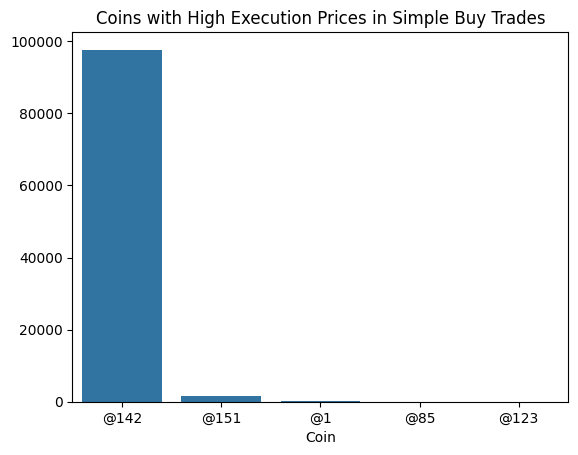

In [28]:
##Coins with High Execution Prices in Simple Buy Trades
coin_sell=final_df[final_df['Direction']=='Buy']
coin_sell_p=coin_sell.groupby('Coin')['Execution Price'].max().sort_values(ascending=False).head(5)
sns.barplot(x=coin_sell_p.index,y=coin_sell_p.values)
plt.title('Coins with High Execution Prices in Simple Buy Trades')
plt.show()

## Again @142 is the Coin With High Execution Price in Simple Sell Trade

In [29]:
final_df['classification'].value_counts()

,count
classification,
Greed,90295
Fear,83237
Neutral,37686


In [30]:
final_df['Crossed'].value_counts()

,count
Crossed,
True,128403
False,82815


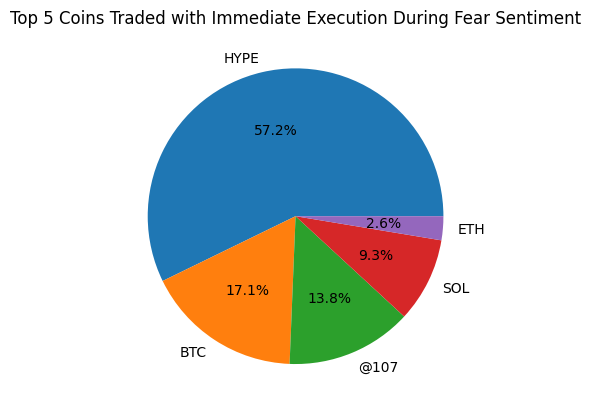

In [32]:
##Top 5 Coins Traded with Immediate Execution During Fear Sentiment
cross_true=final_df[(final_df['Crossed']==True) & (final_df['classification']=='Fear')]
cross_true_coins_count=cross_true['Coin'].value_counts().head(5)
plt.pie(cross_true_coins_count,labels=cross_true_coins_count.index,autopct='%1.1f%%')
plt.title('Top 5 Coins Traded with Immediate Execution During Fear Sentiment')
plt.show()

## HYPE is the most traded Coin with Immediate Execution during Fear Sentiment

In [31]:
final_df['Timestamp'].value_counts()

,count
Timestamp,
2025-02-25,6246
2025-04-23,6159
2025-02-24,5616
2025-03-12,3968
2025-04-09,3967
...,...
2024-09-05,1
2024-07-08,1
2024-08-29,1


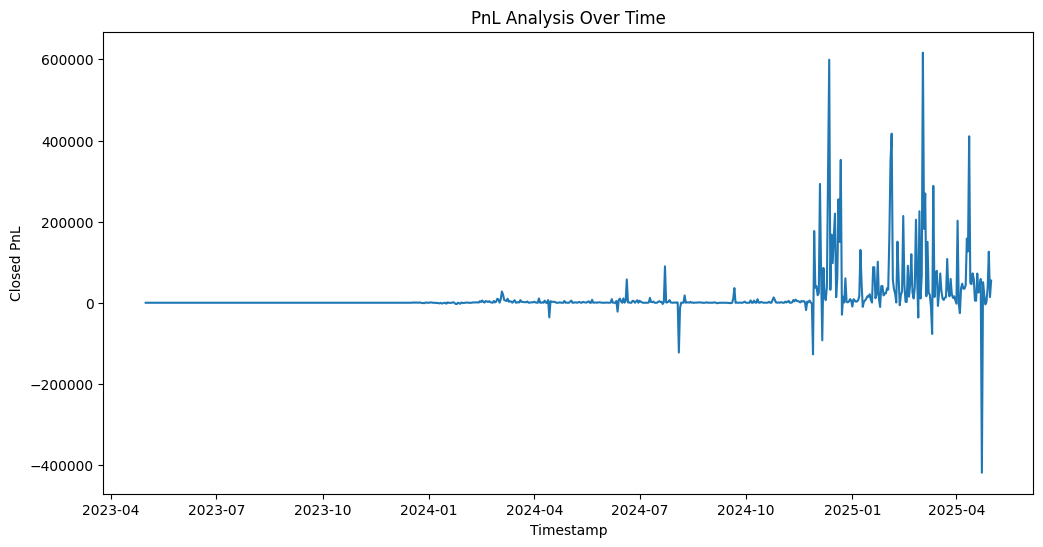

In [32]:
## Pnl Analysis Over Time
pnl_analysis=final_df.groupby('Timestamp')['Closed PnL'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.lineplot(x=pnl_analysis['Timestamp'],y=pnl_analysis['Closed PnL'])
plt.xlabel('Timestamp')
plt.ylabel('Closed PnL')
plt.title('PnL Analysis Over Time')
plt.show()

## Early periods were relatively stable, while later periods display much higher volatility with sharp gains and losses

In [33]:
## Fear Vs Greed PnL Analysis
fear_df=final_df[final_df['classification']=='Fear']
greed_df=final_df[final_df['classification']=='Greed']
fear_df.head()

,Account,Coin,Execution Price,Size Tokens,Size USD,Start Position,Direction,Closed PnL,Order ID,Crossed,Fee,Trade ID,Timestamp,value,classification
190,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,DYDX,0.60975,2834.9,1728.58,0.0,Open Long,0.0,77138632929,True,0.580802,9.810000e+14,2025-03-04,15.0,Fear
191,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,DYDX,0.60975,190.9,116.40,2834.9,Open Long,0.0,77138632929,True,0.039110,8.320000e+14,2025-03-04,15.0,Fear
192,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,DYDX,0.60976,2818.6,1718.67,3025.8,Open Long,0.0,77138632929,True,0.577472,7.030000e+14,2025-03-04,15.0,Fear
193,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,DYDX,0.60981,3689.6,2249.95,5844.4,Open Long,0.0,77138632929,True,0.755984,8.730000e+14,2025-03-04,15.0,Fear
194,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,DYDX,0.61007,3688.1,2250.00,9534.0,Open Long,0.0,77138632929,True,0.755999,9.680000e+14,2025-03-04,15.0,Fear


In [34]:
##It is observed that during Fear sentiment periods, traders mostly opened long positions.
fear_df['Direction'].value_counts()

,count
Direction,
Open Long,24829
Close Long,23501
Open Short,14061
Close Short,12338
Sell,4406
Buy,4014
Spot Dust Conversion,45
Short > Long,24
Long > Short,19


In [35]:
##It is observed that during Greed sentiment periods, traders mostly opened short positions.
greed_df=final_df[final_df['classification']=='Greed']
greed_df['Direction'].value_counts()

,count
Direction,
Open Short,19327
Close Short,17819
Close Long,15184
Open Long,14844
Sell,13150
Buy,9817
Spot Dust Conversion,87
Short > Long,34
Long > Short,23


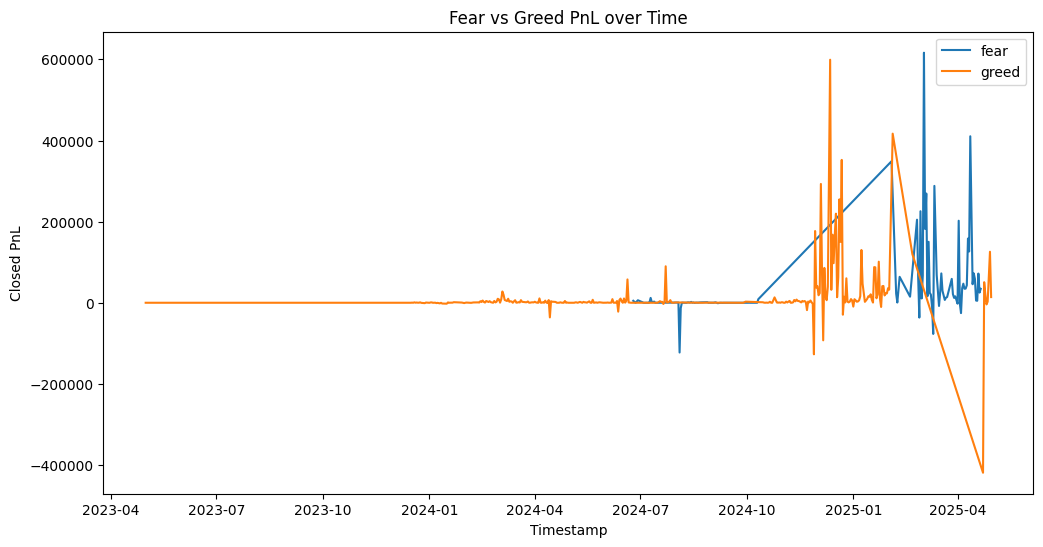

In [36]:
## Fear vs Greed PnL over Time
fear_pnl=fear_df.groupby('Timestamp')['Closed PnL'].sum().reset_index()
greed_pnl=greed_df.groupby('Timestamp')['Closed PnL'].sum().reset_index()
plt.figure(figsize=(12,6))
sns.lineplot(x=fear_pnl['Timestamp'],y=fear_pnl['Closed PnL'],label='fear')
sns.lineplot(x=greed_pnl['Timestamp'],y=greed_pnl['Closed PnL'],label='greed')
plt.title("Fear vs Greed PnL over Time")
plt.show()

## While both sentiments show volatility, Greed periods exhibit sharper spikes, whereas Fear periods show more uneven and abrupt swings, indicating higher uncertainty in trader outcomes


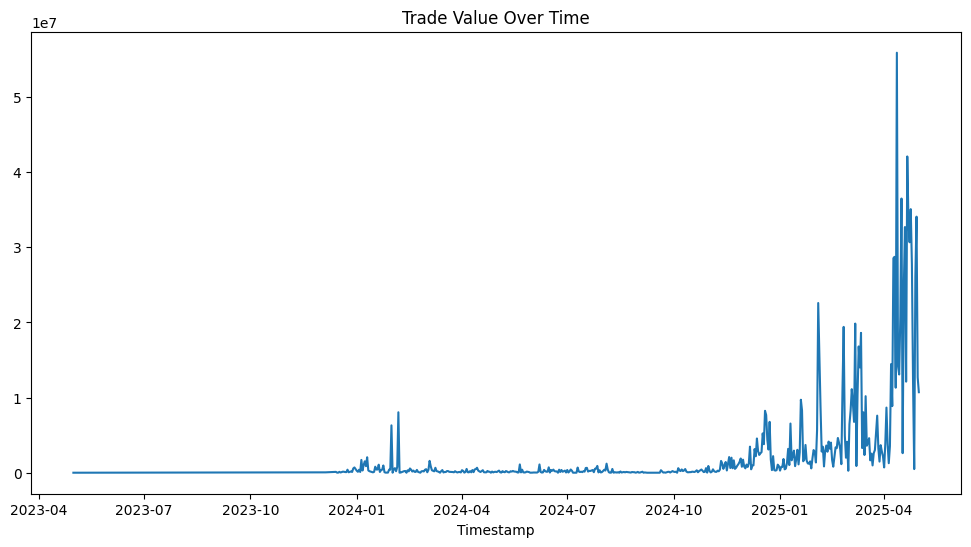

In [37]:
##Trade Value (USD) Over Time
size_usd_timeline=final_df.groupby('Timestamp')['Size USD'].sum()
plt.figure(figsize=(12,6))
sns.lineplot(x=size_usd_timeline.index,y=size_usd_timeline.values)
plt.title('Trade Value Over Time')
plt.show()

## Trade Value has become more volatile in 2025

In [38]:
final_df['classification'].value_counts()

,count
classification,
Greed,90295
Fear,83237
Neutral,37686


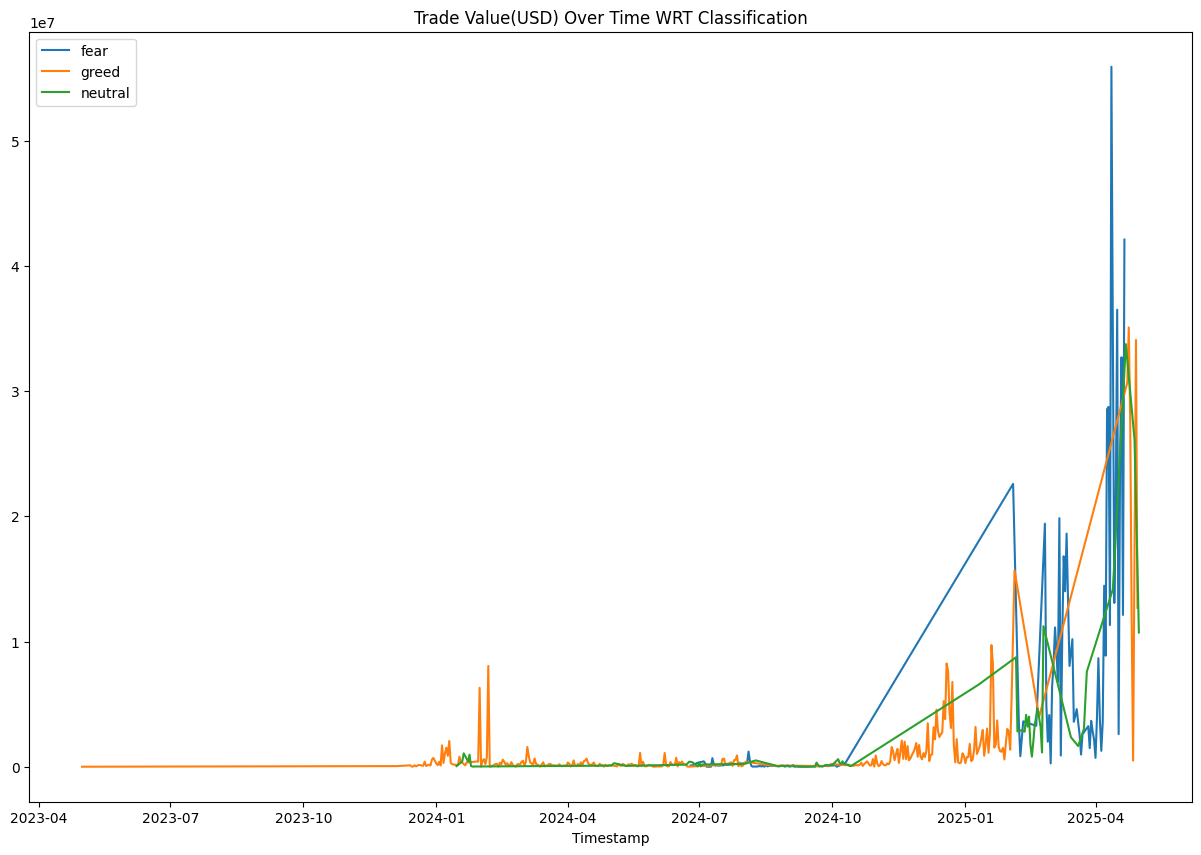

In [39]:
##Trade Value (USD) Over Time WRT Classification
fear_t_df=final_df[final_df['classification']=='Fear']
greed_t_df=final_df[final_df['classification']=='Greed']
neutral_t_df=final_df[final_df['classification']=='Neutral']

fear_t_time=fear_t_df.groupby('Timestamp')['Size USD'].sum()
greed_t_time=greed_t_df.groupby('Timestamp')['Size USD'].sum()
neutral_t_time=neutral_t_df.groupby('Timestamp')['Size USD'].sum()

plt.figure(figsize=(15,10))
sns.lineplot(x=fear_t_time.index,y=fear_t_time.values,label='fear')
sns.lineplot(x=greed_t_time.index,y=greed_t_time.values,label='greed')
sns.lineplot(x=neutral_t_time.index,y=neutral_t_time.values,label='neutral')
plt.title('Trade Value(USD) Over Time WRT Classification')
plt.show()

## Trade value has increased sharply over time across all sentiment categories, with Fear and Greed periods exhibiting the largest spikes in trading activity

Text(0.5, 1.0, 'Top 5 Accounts by Trade Value (USD) During Fear Sentiment')

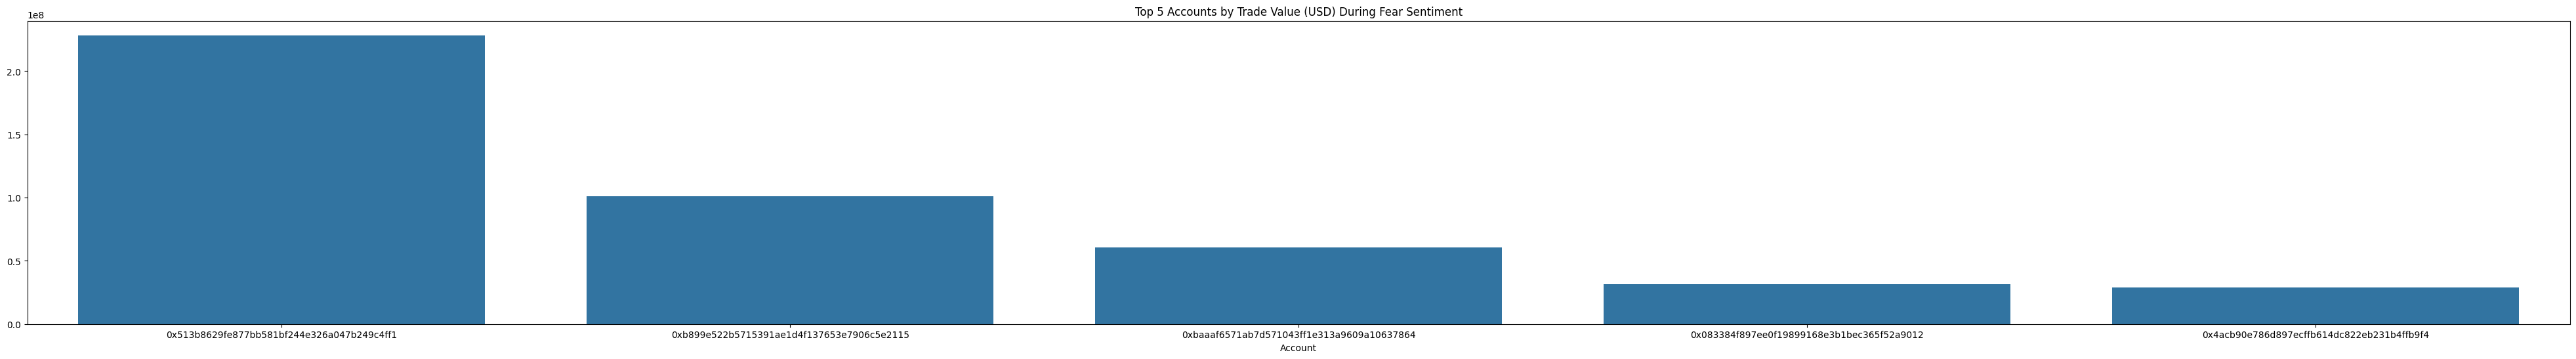

In [40]:
## Top 5 Accounts by Trade Value (USD) During Fear Sentiment
acc=final_df[final_df['classification']=='Fear']
acc_size=acc.groupby('Account')['Size USD'].sum().sort_values(ascending=False).head(5)
plt.figure(figsize=(50,6))
sns.barplot(x=acc_size.index,y=acc_size.values)
plt.title("Top 5 Accounts by Trade Value (USD) During Fear Sentiment")

## 0x513b8629fe877bb581bf244e326a047b248c4ff1 has dominated trading in fearful **market**

Text(0.5, 1.0, 'Top 5 Accounts by Trade Value (USD) During Greed Sentiment')

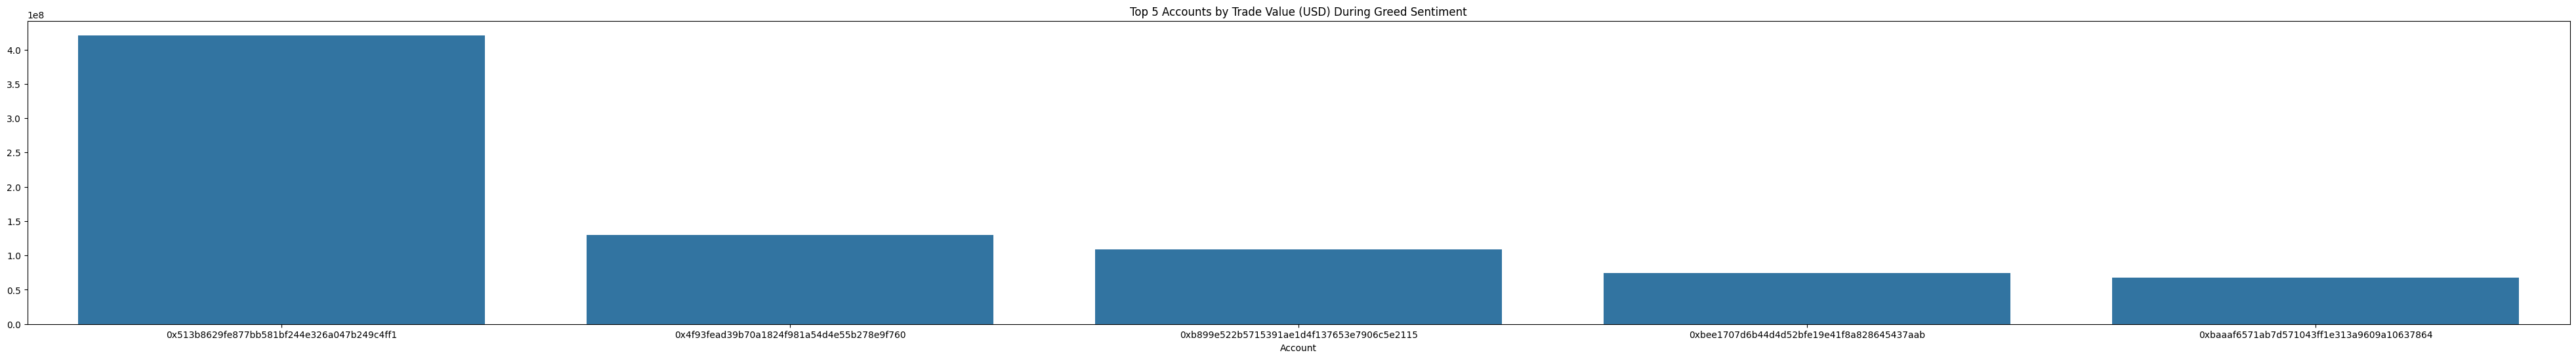

In [42]:
## Top 5 Accounts by Trade Value (USD) During Greed Sentiment
acc_greed=final_df[final_df['classification']=='Greed']
acc_greed_size=final_df.groupby('Account')['Size USD'].sum().sort_values(ascending=False).head(5)
plt.figure(figsize=(50,6))
sns.barplot(x=acc_greed_size.index,y=acc_greed_size.values)
plt.title("Top 5 Accounts by Trade Value (USD) During Greed Sentiment")

## Again 0x513b8629fe877bb581bf244e326a047b248c4ff1 is consistent in performance and has also dominated trading in greedful market

In [41]:
final_df['Start Position'].value_counts()

,count
Start Position,
0.00,4085
0.01,121
1.00,83
50.00,64
25.00,40
...,...
84949.72,1
84962.20,1
84967.16,1


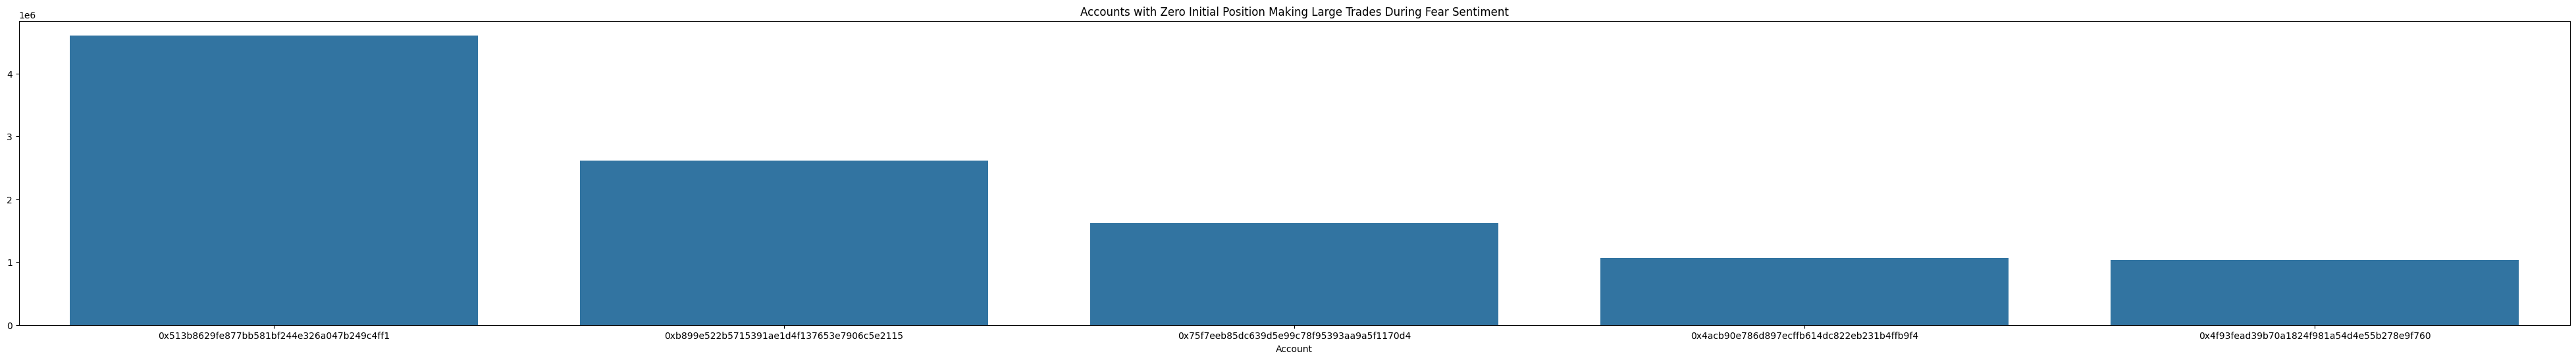

In [43]:
##Accounts with Zero Initial Position Making Large Trades During Fear Sentiment
acc_nothing=final_df[final_df['Start Position']==0.00]
acc_nothing_fear=acc_nothing[acc_nothing['classification']=='Fear']
acc_grp_fear=acc_nothing_fear.groupby('Account')['Size USD'].sum().sort_values(ascending=False).head(5)
plt.figure(figsize=(50,6))
sns.barplot(x=acc_grp_fear.index,y=acc_grp_fear.values)
plt.title('Accounts with Zero Initial Position Making Large Trades During Fear Sentiment')
plt.show()

## Most important thing is 0x513b8629fe877bb581bf244e326a047b248c4ff1 started trading with zero initial position and still dominated the market

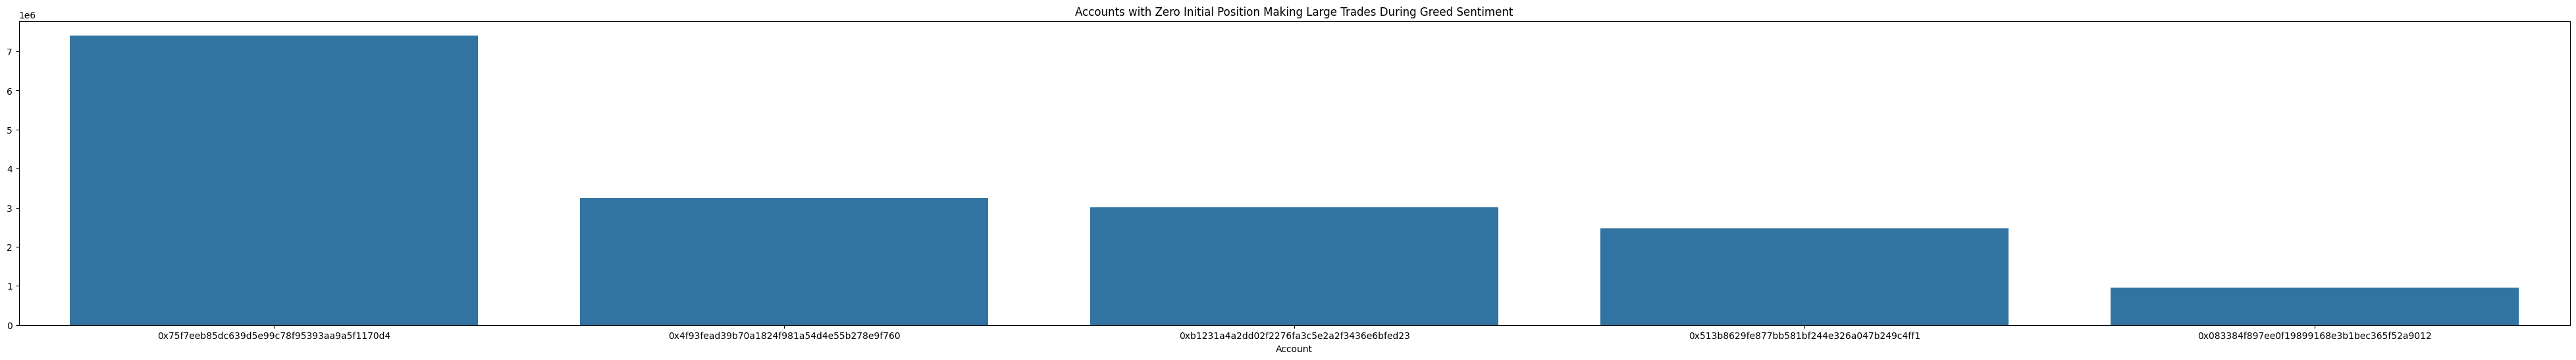

In [45]:
##Accounts with Zero Initial Position Making Large Trades During Greed Sentiment
acc_nothing_greed=acc_nothing[acc_nothing['classification']=='Greed']
acc_grp_greed=acc_nothing_greed.groupby('Account')['Size USD'].sum().sort_values(ascending=False).head(5)
plt.figure(figsize=(50,6))
sns.barplot(x=acc_grp_greed.index,y=acc_grp_greed.values)
plt.title("Accounts with Zero Initial Position Making Large Trades During Greed Sentiment")
plt.show()

## 0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4 dominated greedful market with zero initial position

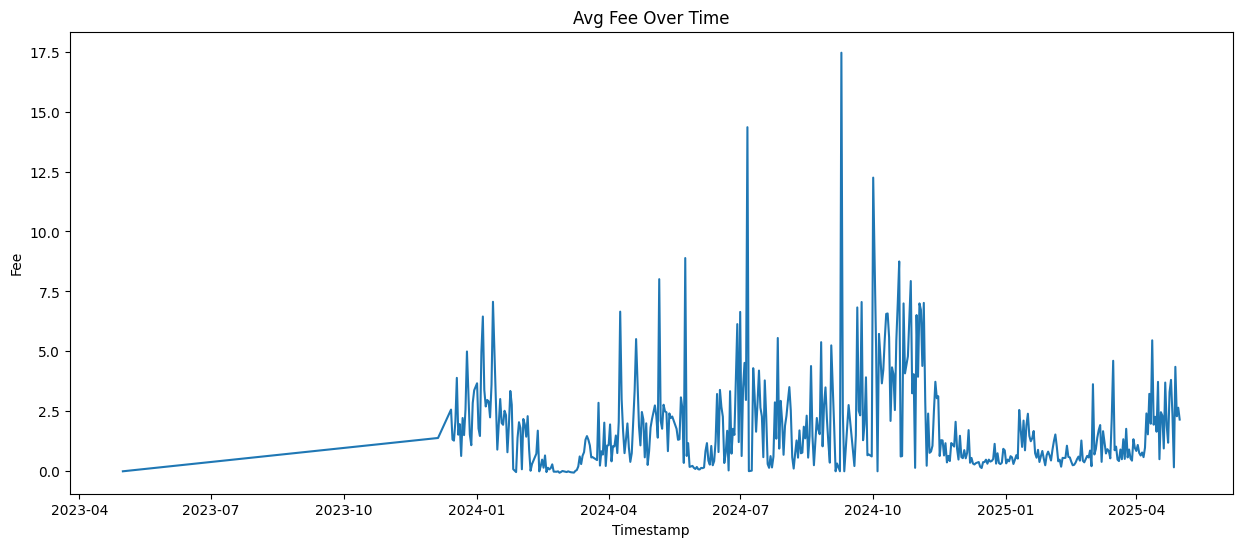

In [44]:
#Avg Fee Over Time
fee_over_time=final_df.groupby('Timestamp')['Fee'].mean().reset_index()
plt.figure(figsize=(15,6))
plt.title("Avg Fee Over Time")
sns.lineplot(x=fee_over_time['Timestamp'],y=fee_over_time['Fee'])
plt.show()

## Average trading fees increase over time and become more volatile in later periods, indicating higher trading activity and larger trade sizes

In [46]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 211218 entries, 0 to 211223
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Account          211218 non-null  object 
 1   Coin             211218 non-null  object 
 2   Execution Price  211218 non-null  float64
 3   Size Tokens      211218 non-null  float64
 4   Size USD         211218 non-null  float64
 5   Start Position   211218 non-null  float64
 6   Direction        211218 non-null  object 
 7   Closed PnL       211218 non-null  float64
 8   Order ID         211218 non-null  int64  
 9   Crossed          211218 non-null  bool   
 10  Fee              211218 non-null  float64
 11  Trade ID         211218 non-null  float64
 12  Timestamp        211218 non-null  object 
 13  value            211218 non-null  float64
 14  classification   211218 non-null  object 
dtypes: bool(1), float64(8), int64(1), object(5)
memory usage: 24.4+ MB


In [47]:
num_features=[feature for feature in final_df.columns if final_df[feature].dtypes=='float64' or final_df[feature].dtypes=='int64']
print(num_features)

['Execution Price', 'Size Tokens', 'Size USD', 'Start Position', 'Closed PnL', 'Order ID', 'Fee', 'Trade ID', 'value']


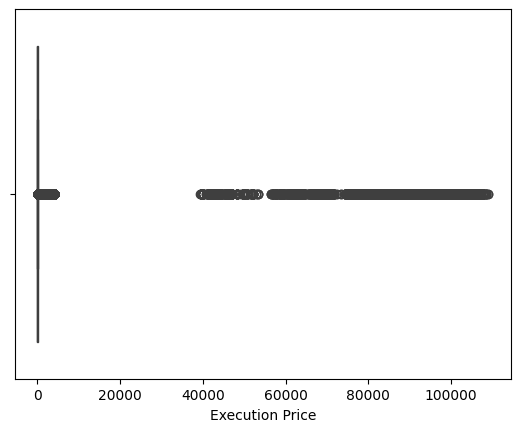

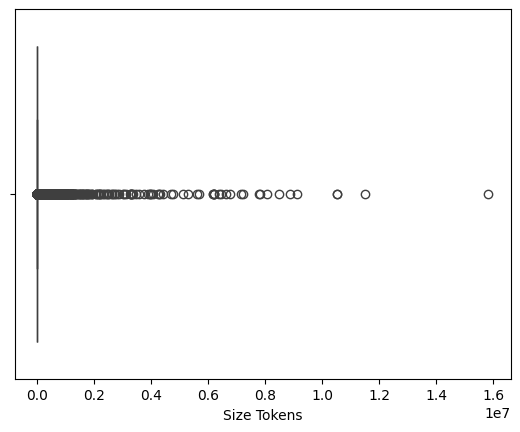

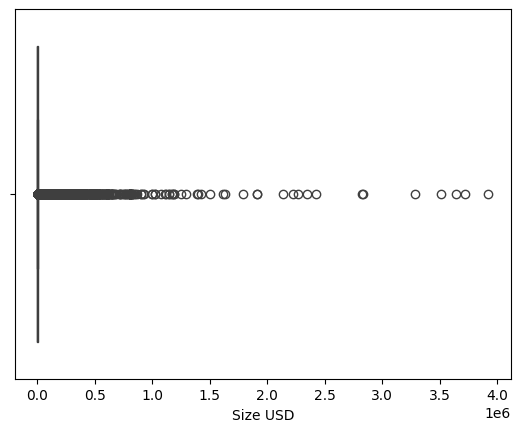

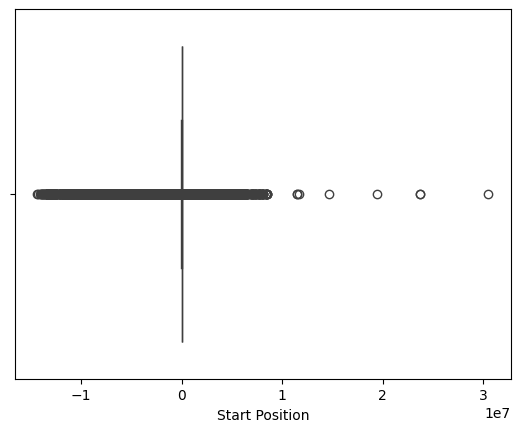

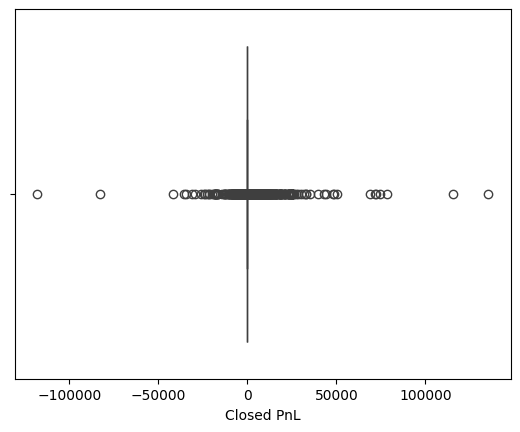

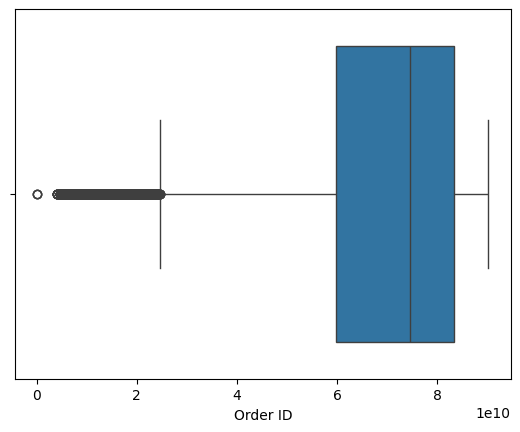

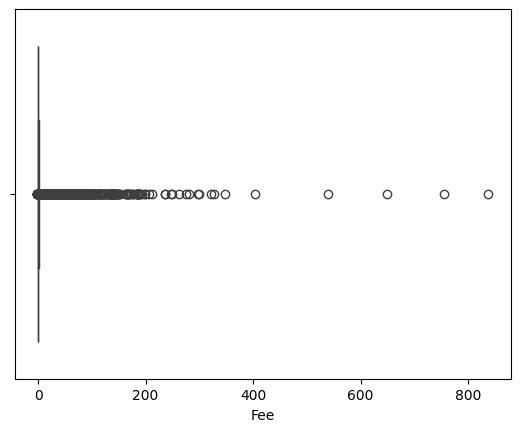

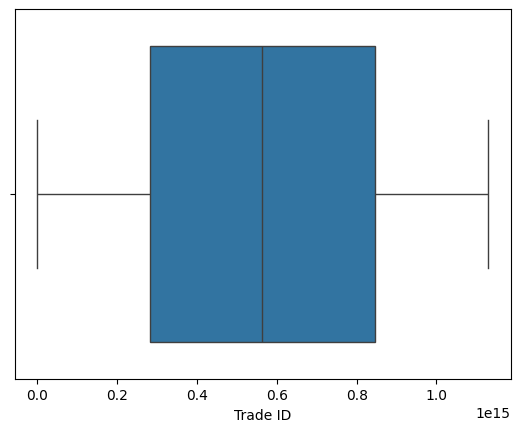

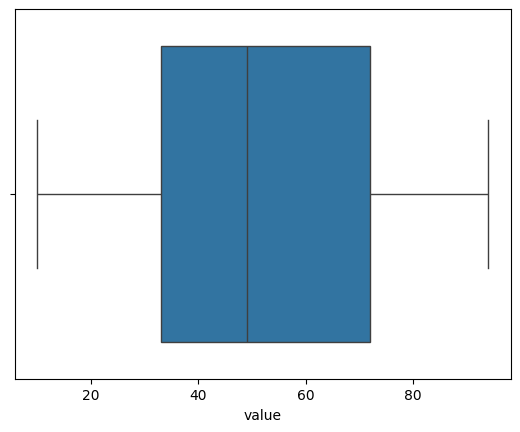

In [51]:
for i in num_features:
  sns.boxplot(x=i,data=final_df)
  plt.show()

## Indication of presence of Outliers

<Axes: >

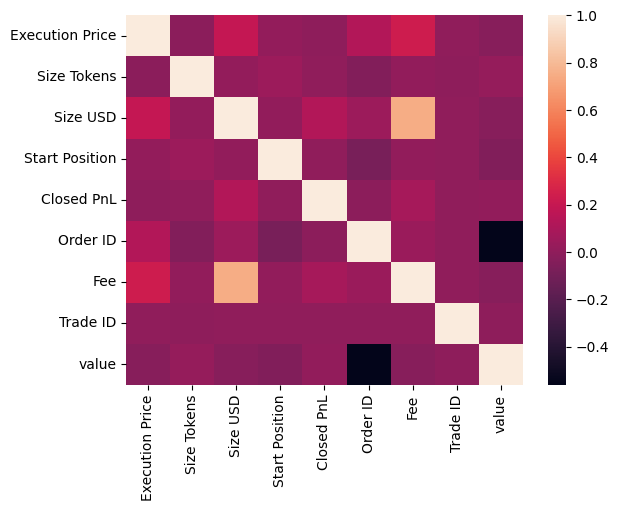

In [48]:
sns.heatmap(final_df[num_features].corr())

## The heatmap shows relationships between numerical trading variables, with strong correlations between trade size (USD) and fees, while most other features exhibit weak or no direct correlation